# Week 4 · The Higgs Project: Low-Level vs. High-Level Features

**AI SCI 290A, Tuesday of Week 4**

We have collision events from a simulated particle physics experiment. Some are **signal**: a process that produces a new heavy Higgs boson. The rest are **background**: ordinary processes that leave similar traces in the detector. The task is to tell them apart.

Each event comes with two kinds of features:

- **21 low-level features:** what the detector measures directly. The momentum and direction of one lepton (an electron or muon), the missing transverse momentum (from an undetected neutrino), and four jets (sprays of particles), each with a flag for whether it looks like it came from a b quark.
- **7 high-level features:** invariant masses that physicists compute from the low-level features, using what they know about the decay chain. For example, `m_bb` is the mass of the system of two b-jets, which peaks near 125 GeV if they came from a Higgs boson.

The high-level features are **functions of the low-level ones**. They can't contain any information the low-level features lack; they can only make some of it easier to see.

**The question for today:** a shallow network does better with the high-level features, because physicists have done part of the work for it. Can a deeper network learn that work itself from the low-level features, and even do better?

Today we will:

1. Get a short introduction to PyTorch
2. Load the data and look at it
3. Set baselines: logistic regression, and a shallow network on each feature set
4. Explore network depth on the low-level features
5. Tune other settings: width, learning rate, dropout
6. Compare the best models on the test set
7. See how the answer depends on the amount of training data

This notebook is written to run on two data files. The small file (25,000 events) runs in a few minutes on a laptop. The full file (11 million events) takes hours; your instructor will run it and show you the results.

*Reference: P. Baldi, P. Sadowski and D. Whiteson, "Searching for exotic particles in high-energy physics with deep learning," Nature Communications 5, 4308 (2014).*

## 0. Settings

Choose the data file here. Everything below adapts to its size.

In [27]:
# The small sample (posted on Canvas)
#DATA_FILE = "data/HIGGS_25k.csv.gz"

# The full dataset (11 million events): uncomment to use it
DATA_FILE = "data/HIGGS.csv.gz"

# Use only the first N events of the file (None = all of them)
N_EVENTS = None

## 1. Imports

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import time

# should be
# NumPy: 1.26.4
# Pandas: 2.3.3
# scikit-learn: 1.7.2
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 1.26.4
Pandas: 2.3.3
scikit-learn: 1.7.2


In [29]:
# Import torch, check for GPU
# should be:
# Torch v: 2.7.1
# CUDA available: False
import torch
print("Torch v:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch v: 2.7.1
CUDA available: False


In [30]:
# splits dataset into training, validation and test sets
from sklearn.model_selection import train_test_split

# preprocesses dataset to make it easier to learn
from sklearn.preprocessing import StandardScaler

# calculates performance metrics
from sklearn.metrics import roc_auc_score, roc_curve

import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

## 2. A short introduction to PyTorch

Last week we used scikit-learn's `MLPClassifier`, which hides the training loop inside `fit()`. **PyTorch** is the library most researchers use to build neural networks. It shows every step, which makes it more work to write, but lets you change anything.

Four ideas cover almost everything:

| Idea | In PyTorch |
|---|---|
| Data | a **tensor**: like a NumPy array, but it can track gradients and run on a GPU |
| Model | an `nn.Module`, often built from layers with `nn.Sequential` |
| Loss | a function measuring how wrong the predictions are, like `nn.BCELoss` |
| Optimizer | updates the weights to lower the loss, like `optim.Adam` |

### Tensors

In [31]:
a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print(a)
print("shape:", a.shape)

# Converting from and to NumPy
b = torch.tensor(np.array([5.0, 6.0]), dtype=torch.float32)
print(b.numpy())

tensor([[1., 2.],
        [3., 4.]])
shape: torch.Size([2, 2])
[5. 6.]


### A model

`nn.Linear(3, 4)` is a layer that takes 3 numbers and outputs 4 weighted sums. `nn.ReLU()` sets negative values to 0. `nn.Sigmoid()` squashes a number into a probability between 0 and 1. `nn.Sequential` chains layers together.

In [32]:
torch.manual_seed(0)

tiny = nn.Sequential(
    nn.Linear(3, 4),   # 3 inputs -> 4 hidden units
    nn.ReLU(),
    nn.Linear(4, 1),   # 4 hidden units -> 1 output
    nn.Sigmoid(),      # output -> probability
)
print(tiny)

x = torch.tensor([[0.5, -1.0, 2.0],
                  [1.0,  0.0, 0.0]])   # two examples, three features each
print("Predictions:", tiny(x).detach().numpy().ravel())

Sequential(
  (0): Linear(in_features=3, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
  (3): Sigmoid()
)
Predictions: [0.542832   0.53586036]


### One training step

Every training loop repeats the same five lines:

1. `optimizer.zero_grad()`: clear the old gradients
2. `pred = model(x)`: make predictions
3. `loss = loss_fn(pred, y)`: measure how wrong they are
4. `loss.backward()`: work out how each weight affects the loss (the gradient)
5. `optimizer.step()`: nudge every weight to reduce the loss

Watch the loss fall as we repeat these steps on our two examples:

In [33]:
y_tiny = torch.tensor([[1.0], [0.0]])   # the right answers for the two examples

loss_fn = nn.BCELoss()                  # binary cross-entropy = log loss, as last week
optimizer = optim.Adam(tiny.parameters(), lr=0.05)

for step in range(6):
    optimizer.zero_grad()
    pred = tiny(x)
    loss = loss_fn(pred, y_tiny)
    loss.backward()
    optimizer.step()
    print(f"step {step}: loss {loss.item():.4f}")

step 0: loss 0.6893
step 1: loss 0.6761
step 2: loss 0.6649
step 3: loss 0.6525
step 4: loss 0.6387
step 5: loss 0.6230


That's all a neural network does during training, repeated over many batches of real data. The `train_model` function in Section 5 is these five lines inside two loops: one over batches, one over epochs.

## 3. Load the data

The file has no header row, so we supply the column names. We read the numbers as 32-bit floats, which halves the memory needed for the full file.

In [34]:
# these are the names
# we need them because the CSV file doesn't have labelled columns; this makes it easier to understand later
columns = [
    "label",
    "lep_pt", "lep_eta", "lep_phi",
    "met", "met_phi",
    "jet1_pt", "jet1_eta", "jet1_phi", "jet1_btag",
    "jet2_pt", "jet2_eta", "jet2_phi", "jet2_btag",
    "jet3_pt", "jet3_eta", "jet3_phi", "jet3_btag",
    "jet4_pt", "jet4_eta", "jet4_phi", "jet4_btag",
    "m_jj", "m_jjj", "m_lv", "m_jlv", "m_bb", "m_wbb", "m_wwbb"
]
LOW_LEVEL = columns[1:22]    # 21 features
HIGH_LEVEL = columns[22:]    # 7 features

t0 = time.time()
df = pd.read_csv(DATA_FILE, names=columns, nrows=N_EVENTS, dtype=np.float32)
print(f"Loaded {len(df):,} events in {time.time() - t0:.0f} s")
print(f"Signal fraction: {df['label'].mean():.3f}")
df.head()

Loaded 11,000,000 events in 58 s
Signal fraction: 0.530


,label,lep_pt,lep_eta,lep_phi,met,met_phi,jet1_pt,jet1_eta,jet1_phi,jet1_btag,...,jet4_eta,jet4_phi,jet4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487


### Settings that depend on the data size

The full dataset is 440 times bigger than the small one, so training runs differently. These settings are chosen automatically.

In [35]:
FULL = len(df) > 1_000_000

if FULL:
    BATCH_SIZE = 1024       # bigger batches: fewer, faster steps per epoch
    MAX_EPOCHS = 40
    PATIENCE = 5            # stop if validation AUC hasn't improved in this many epochs
    WIDTH = 300             # hidden units per layer, as in the 2014 paper
else:
    BATCH_SIZE = 256
    MAX_EPOCHS = 60
    PATIENCE = 10
    WIDTH = 128

# The width, learning-rate and dropout scans in Section 8 add several more models.
# On the full dataset each model can take an hour or more on a laptop CPU, so they're off by default there.
RUN_TUNING_SCANS = not FULL

print("Full dataset" if FULL else "Small sample", f"| batch size {BATCH_SIZE}, up to {MAX_EPOCHS} epochs, width {WIDTH}")

Full dataset | batch size 1024, up to 40 epochs, width 300


### Look at the features

One histogram per feature, signal and background overlaid. With the full file we plot a random 200,000 events, which is plenty to see the shapes.

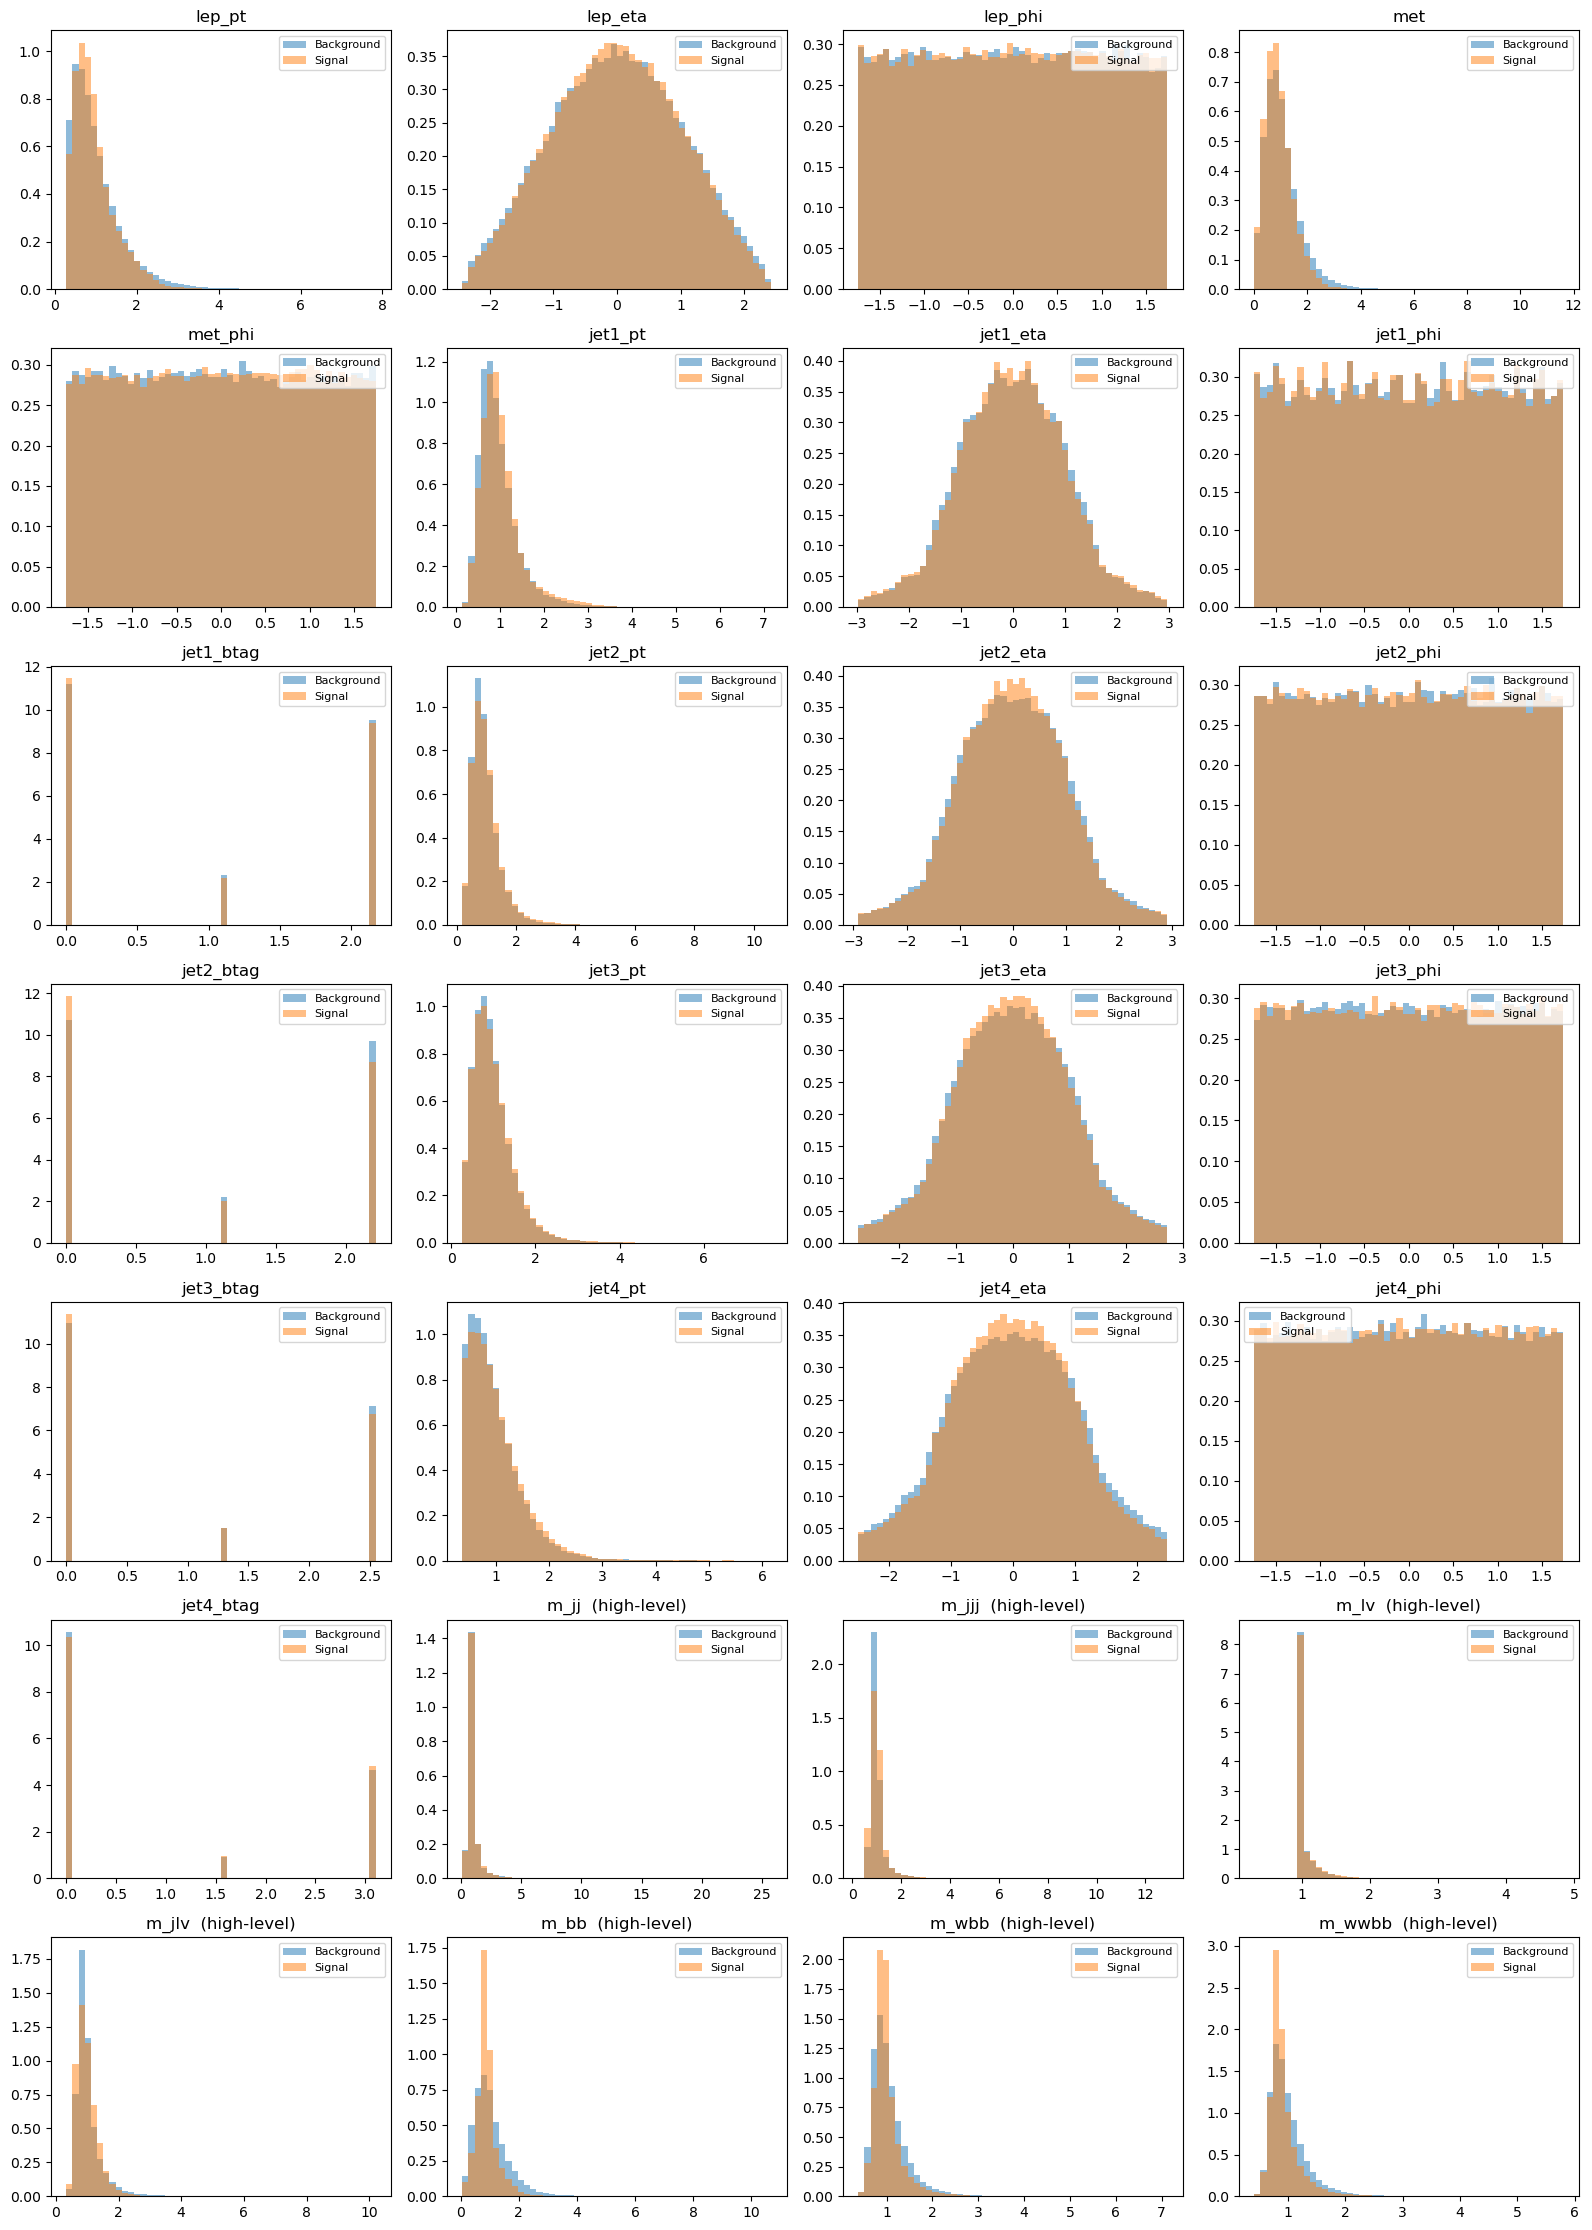

In [36]:
plot_df = df.sample(n=min(len(df), 200_000), random_state=0)
signal = plot_df[plot_df["label"] == 1]
background = plot_df[plot_df["label"] == 0]

features = columns[1:]
ncols = 4
nrows = int(np.ceil(len(features) / ncols))

plt.figure(figsize=(16, 3.2 * nrows))
for i, feature in enumerate(features):
    plt.subplot(nrows, ncols, i + 1)
    n, b, _ = plt.hist(background[feature], bins=50, density=True, alpha=0.5, label="Background")
    plt.hist(signal[feature], bins=b, density=True, alpha=0.5, label="Signal")
    plt.title(feature + ("  (high-level)" if feature in HIGH_LEVEL else ""))
    plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Question:** compare the low-level histograms (the first 21) with the high-level ones (the last 7). Which set shows a clearer difference between signal and background? Why might that be?

## 4. Training, validation and test sets

As last week: we fit on the training set, choose settings with the validation set, and look at the test set once at the end.

In [37]:
X = df[features].values
y = df["label"].values
if FULL:
    del df, plot_df, signal, background   # free memory: we only need X and y from here on

X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.25, random_state=42, stratify=y_rest)
del X_rest, y_rest

# standardize, fitting on the training set only
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# column positions of each feature set
LOW = list(range(0, 21))
HIGH = list(range(21, 28))
ALL = list(range(0, 28))

print(f"Training {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,}")

Training 6,600,000 | validation 2,200,000 | test 2,200,000


## 5. The model and the training loop

The network is a stack of layers. `num_hidden_layers` sets the **depth** and `hidden_dim` the **width**. We've added an optional **dropout** layer after each hidden layer: during training it randomly switches off a fraction of the units, which makes it harder for the network to memorize the training events.

In [38]:
# Build a feed-forward neural network in PyTorch
class FFNN(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_hidden_layers=2, dropout=0.0):
        super().__init__()

        layers = []
        in_dim = input_dim

        # Hidden layers
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_dim = hidden_dim

        # Output layer
        layers.append(nn.Linear(in_dim, 1))
        layers.append(nn.Sigmoid())

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

The training function trains for up to `epochs` epochs. After each epoch it scores the model on the **validation** set. It keeps a copy of the best version so far, and stops early if the validation AUC hasn't improved for `patience` epochs.

On the full dataset it also halves the learning rate whenever the validation AUC stalls for 2 epochs (`lr_decay`). Smaller steps help a model settle into a better minimum late in training.

In [39]:
def predict(model, X, chunk=200_000):
    """Apply a model to an array, in chunks so the full dataset fits in memory."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), chunk):
            out.append(model(torch.from_numpy(X[i:i + chunk])).numpy().ravel())
    return np.concatenate(out)


def train_model(model, X_train, y_train, X_val, y_val,
                epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, lr=1e-3,
                patience=PATIENCE, lr_decay=FULL, verbose=True, plot=False):
    """Train a PyTorch binary classifier with early stopping on validation AUC.
    Returns a dict with the loss and AUC history and the best validation AUC."""

    # what to minimize and how
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # optionally halve the learning rate when the validation AUC stops improving for 2 epochs
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2) if lr_decay else None

    # make it torch tensors
    train_dataset = TensorDataset(torch.from_numpy(X_train),
                                  torch.from_numpy(y_train.astype(np.float32)).view(-1, 1))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    history = {"train_loss": [], "val_auc": []}
    best_auc, best_state, best_epoch = 0.0, None, 0
    t0 = time.time()

    # main loop
    for epoch in range(epochs):
        # ---- Training ----
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        history["train_loss"].append(running_loss / len(train_loader))

        # ---- Validation ----
        val_auc = roc_auc_score(y_val, predict(model, X_val))
        history["val_auc"].append(val_auc)
        if scheduler is not None:
            scheduler.step(val_auc)

        if val_auc > best_auc:
            best_auc, best_epoch = val_auc, epoch + 1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
            print(f"Epoch {epoch+1:02d}: train loss = {history['train_loss'][-1]:.4f}, "
                  f"val AUC = {val_auc:.4f}  ({time.time() - t0:.0f} s)")

        # ---- Early stopping ----
        if epoch + 1 - best_epoch >= patience:
            if verbose:
                print(f"Stopping: no improvement since epoch {best_epoch}")
            break

    # go back to the best version
    model.load_state_dict(best_state)
    history["best_auc"], history["best_epoch"] = best_auc, best_epoch

    if plot:
        fig, ax1 = plt.subplots(figsize=(7, 4))
        ax1.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], color="gray", label="Training loss")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Training loss")
        ax2 = ax1.twinx()
        ax2.plot(range(1, len(history["val_auc"]) + 1), history["val_auc"], color="C0", label="Validation AUC")
        ax2.axvline(best_epoch, color="C0", ls=":", lw=1)
        ax2.set_ylabel("Validation AUC", color="C0")
        ax1.set_title(f"Best validation AUC {best_auc:.3f} at epoch {best_epoch}")
        plt.show()

    if verbose:
        print(f"Best validation AUC: {best_auc:.4f} at epoch {best_epoch}  ({time.time() - t0:.0f} s total)")
    return history

We'll record every model we try in one table:

In [40]:
results = []   # one row per model
models = {}    # the trained models, by name

def run(name, cols, depth, width=WIDTH, lr=1e-3, dropout=0.0, X_tr=None, y_tr=None, seed=0, **kw):
    """Build, train and record one model. Returns the trained model."""
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    torch.manual_seed(seed)
    model = FFNN(len(cols), hidden_dim=width, num_hidden_layers=depth, dropout=dropout)
    h = train_model(model, X_tr[:, cols], y_tr, X_val[:, cols], y_val, lr=lr, **kw)
    results.append({"name": name, "features": {21: "low", 7: "high", 28: "all"}[len(cols)],
                    "depth": depth, "width": width, "lr": lr, "dropout": dropout,
                    "n_train": len(X_tr), "val_auc": h["best_auc"], "best_epoch": h["best_epoch"]})
    models[name] = model
    return model

## 6. Baselines

### Logistic regression

A note on computing AUC: it needs a **score**, the predicted probability, from `predict_proba`. If you pass the 0/1 output of `predict` instead, you get the AUC of a single threshold, which is lower and not comparable.

In [41]:
from sklearn.linear_model import LogisticRegression

lr_models = {}
for name, cols in [("low", LOW), ("high", HIGH), ("all", ALL)]:
    clf = LogisticRegression(max_iter=1000).fit(X_train[:, cols], y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val[:, cols])[:, 1])
    lr_models[name] = clf
    print(f"Logistic regression, {name} features: validation AUC {auc:.3f}")

Logistic regression, low features: validation AUC 0.594
Logistic regression, high features: validation AUC 0.647
Logistic regression, all features: validation AUC 0.685


### A shallow network on each feature set

One hidden layer. This is roughly what was standard in particle physics before deep learning.

Epoch 01: train loss = 0.5695, val AUC = 0.7821  (33 s)
Epoch 05: train loss = 0.5493, val AUC = 0.7900  (162 s)
Epoch 10: train loss = 0.5468, val AUC = 0.7913  (326 s)
Epoch 15: train loss = 0.5450, val AUC = 0.7931  (488 s)
Epoch 20: train loss = 0.5446, val AUC = 0.7934  (647 s)
Epoch 25: train loss = 0.5443, val AUC = 0.7937  (807 s)
Epoch 30: train loss = 0.5435, val AUC = 0.7938  (967 s)
Epoch 35: train loss = 0.5431, val AUC = 0.7947  (1127 s)
Epoch 40: train loss = 0.5428, val AUC = 0.7947  (1286 s)


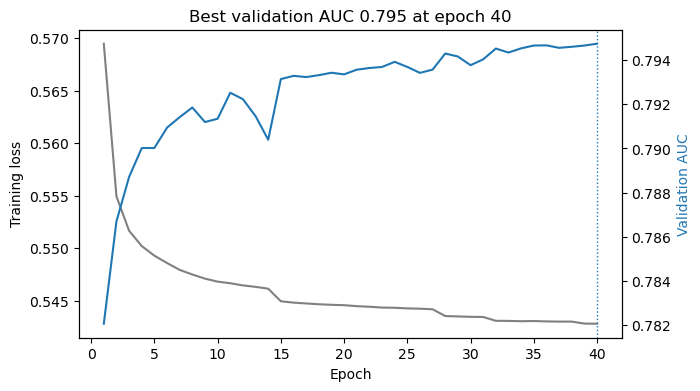

Best validation AUC: 0.7947 at epoch 40  (1286 s total)


In [42]:
shallow_high = run("Shallow, high-level", HIGH, depth=1, plot=True)

Epoch 01: train loss = 0.6189, val AUC = 0.7380  (33 s)
Epoch 05: train loss = 0.5758, val AUC = 0.7661  (165 s)
Epoch 10: train loss = 0.5698, val AUC = 0.7709  (330 s)
Epoch 15: train loss = 0.5676, val AUC = 0.7729  (497 s)
Epoch 20: train loss = 0.5664, val AUC = 0.7726  (665 s)
Epoch 25: train loss = 0.5631, val AUC = 0.7765  (831 s)
Epoch 30: train loss = 0.5613, val AUC = 0.7781  (998 s)
Epoch 35: train loss = 0.5611, val AUC = 0.7783  (1163 s)
Epoch 40: train loss = 0.5602, val AUC = 0.7789  (1329 s)


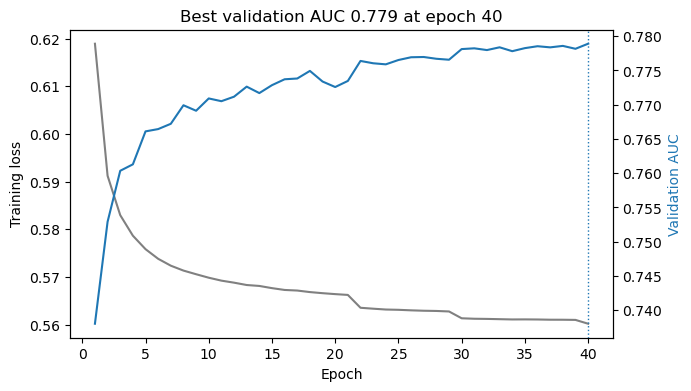

Best validation AUC: 0.7789 at epoch 40  (1329 s total)


In [43]:
shallow_low = run("Shallow, low-level", LOW, depth=1, plot=True)

**Question:** which feature set does the shallow network prefer? What does that tell you about how hard it is to compute the high-level features from the low-level ones?

## 7. Does depth help on the low-level features?

The high-level features are complicated functions of the low-level ones (invariant masses involve square roots of sums of products of momenta). A deeper network can build up complicated functions layer by layer. Let's see if depth helps it learn them.

In [44]:
# depth 1 is the shallow low-level network from Section 6
for depth in [2, 3, 4, 5]:
    run(f"Low-level, depth {depth}", LOW, depth=depth, verbose=False)
    print(f"depth {depth}: validation AUC {results[-1]['val_auc']:.4f} (best epoch {results[-1]['best_epoch']})")

depth 2: validation AUC 0.8427 (best epoch 40)
depth 3: validation AUC 0.8624 (best epoch 40)
depth 4: validation AUC 0.8651 (best epoch 33)
depth 5: validation AUC 0.8670 (best epoch 27)


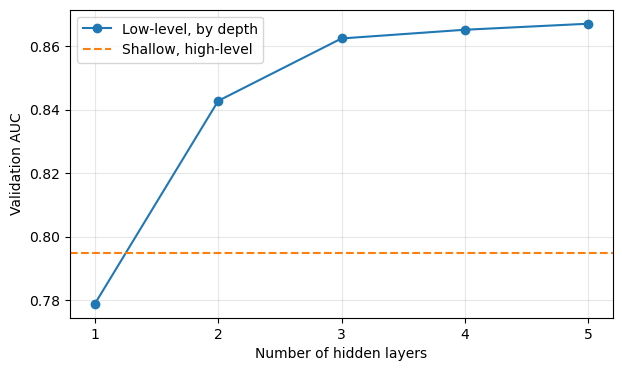

In [45]:
depth_table = pd.DataFrame(results)
depth_table = depth_table[(depth_table["features"] == "low") & (depth_table["width"] == WIDTH)
                          & (depth_table["lr"] == 1e-3) & (depth_table["dropout"] == 0)]

plt.figure(figsize=(7, 4))
plt.plot(depth_table["depth"], depth_table["val_auc"], "o-", label="Low-level, by depth")
shallow_high_auc = next(r["val_auc"] for r in results if r["name"] == "Shallow, high-level")
plt.axhline(shallow_high_auc, color="C1", ls="--", label="Shallow, high-level")
plt.xticks(depth_table["depth"])
plt.xlabel("Number of hidden layers")
plt.ylabel("Validation AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Question:** does the low-level network catch up with the shallow high-level network as you add layers? Look at the `best_epoch` column too: what does it mean if the best epoch comes very early?

*With the small file,* deeper networks reach their best validation score after only a few epochs and then get worse: they overfit. *With the full file,* your instructor will show what happens with 440 times more data.

In [46]:
pd.DataFrame(results).round(4)

,name,features,depth,width,lr,dropout,n_train,val_auc,best_epoch
0,"Shallow, high-level",high,1,300,0.001,0.0,6600000,0.7947,40
1,"Shallow, low-level",low,1,300,0.001,0.0,6600000,0.7789,40
2,"Low-level, depth 2",low,2,300,0.001,0.0,6600000,0.8427,40
3,"Low-level, depth 3",low,3,300,0.001,0.0,6600000,0.8624,40
4,"Low-level, depth 4",low,4,300,0.001,0.0,6600000,0.8651,33
5,"Low-level, depth 5",low,5,300,0.001,0.0,6600000,0.8670,27


## 8. Tuning other hyperparameters

Depth is one **hyperparameter**. Here are three more. We change one at a time, starting from the best depth found above, and compare on the validation set.

- **Width:** hidden units per layer
- **Learning rate:** step size for each weight update
- **Dropout:** fraction of units switched off during training, to fight overfitting

In [47]:
best_depth = int(depth_table.loc[depth_table["val_auc"].idxmax(), "depth"])
print("Starting from depth", best_depth)

if not RUN_TUNING_SCANS:
    print("Tuning scans are off (RUN_TUNING_SCANS = False)")
for w in ([32, 2 * WIDTH] if RUN_TUNING_SCANS else []):   # WIDTH itself was trained in the depth scan
    run(f"Low-level, depth {best_depth}, width {w}", LOW, depth=best_depth, width=w, verbose=False)
    print(f"width {w}: validation AUC {results[-1]['val_auc']:.4f}")

Starting from depth 5
Tuning scans are off (RUN_TUNING_SCANS = False)


In [48]:
for lr in ([1e-4, 1e-2] if RUN_TUNING_SCANS else []):
    run(f"Low-level, depth {best_depth}, lr {lr}", LOW, depth=best_depth, lr=lr, verbose=False)
    print(f"learning rate {lr}: validation AUC {results[-1]['val_auc']:.4f}")

In [49]:
for p in ([0.2, 0.5] if RUN_TUNING_SCANS else []):
    run(f"Low-level, depth {best_depth}, dropout {p}", LOW, depth=best_depth, dropout=p, verbose=False)
    print(f"dropout {p}: validation AUC {results[-1]['val_auc']:.4f}")

In [50]:
table = pd.DataFrame(results).sort_values("val_auc", ascending=False)
table.round(4)

,name,features,depth,width,lr,dropout,n_train,val_auc,best_epoch
5,"Low-level, depth 5",low,5,300,0.001,0.0,6600000,0.8670,27
4,"Low-level, depth 4",low,4,300,0.001,0.0,6600000,0.8651,33
3,"Low-level, depth 3",low,3,300,0.001,0.0,6600000,0.8624,40
2,"Low-level, depth 2",low,2,300,0.001,0.0,6600000,0.8427,40
0,"Shallow, high-level",high,1,300,0.001,0.0,6600000,0.7947,40
1,"Shallow, low-level",low,1,300,0.001,0.0,6600000,0.7789,40


**Question:** which change helped most? With the small file, does any setting get the low-level network past the shallow high-level one?

We changed one setting at a time. Settings interact (the best learning rate can depend on the depth), so a fuller search would try combinations. That gets expensive fast, which is why it pays to think about which settings matter most.

## 9. Using all the features

The high-level features are computed from the low-level ones, so in principle they add nothing new. But they make some information easier to reach. Let's give a network both.

In [51]:
low_rows = table[table["features"] == "low"]
best_low = low_rows.iloc[0]
print("Best low-level settings:", best_low[["depth", "width", "lr", "dropout"]].to_dict())

deep_all = run("Deep, all features", ALL, depth=int(best_low["depth"]), width=int(best_low["width"]),
               lr=float(best_low["lr"]), dropout=float(best_low["dropout"]), verbose=False)
print(f"All features: validation AUC {results[-1]['val_auc']:.4f}")

Best low-level settings: {'depth': 5, 'width': 300, 'lr': 0.001, 'dropout': 0.0}
All features: validation AUC 0.8658


## 10. Final comparison on the test set

We retrain nothing: we take the models chosen with the validation set and score each one on the test set, once.

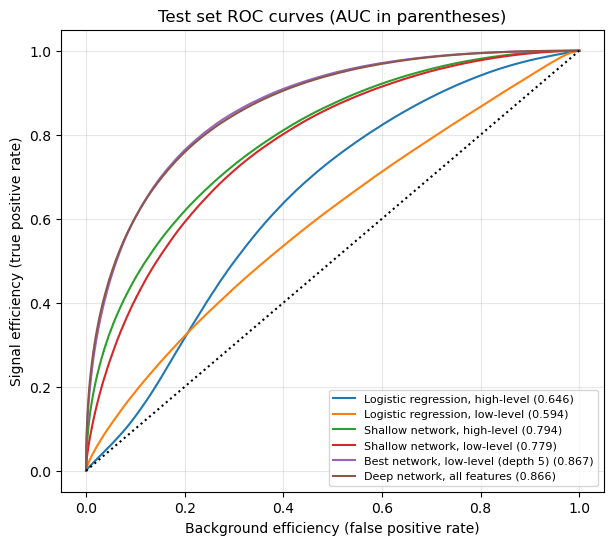

Logistic regression, low-level       0.5939
Logistic regression, high-level      0.6462
Shallow network, low-level           0.7787
Shallow network, high-level          0.7944
Deep network, all features           0.8655
Best network, low-level (depth 5)    0.8668
dtype: float64

In [52]:
best_low_model = models[best_low["name"]]

final = {
    "Logistic regression, high-level": lr_models["high"].predict_proba(X_test[:, HIGH])[:, 1],
    "Logistic regression, low-level": lr_models["low"].predict_proba(X_test[:, LOW])[:, 1],
    "Shallow network, high-level": predict(shallow_high, X_test[:, HIGH]),
    "Shallow network, low-level": predict(shallow_low, X_test[:, LOW]),
    f"Best network, low-level (depth {int(best_low['depth'])})": predict(best_low_model, X_test[:, LOW]),
    "Deep network, all features": predict(deep_all, X_test[:, ALL]),
}

plt.figure(figsize=(7, 6))
test_auc = {}
for name, scores in final.items():
    test_auc[name] = roc_auc_score(y_test, scores)
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} ({test_auc[name]:.3f})")
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("Background efficiency (false positive rate)")
plt.ylabel("Signal efficiency (true positive rate)")
plt.title("Test set ROC curves (AUC in parentheses)")
plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.3)
plt.show()

pd.Series(test_auc).sort_values().round(4)

## 11. How much data does it take?

The low-level features hold all the information, but a network has to *learn* how to extract it. That takes data. Here we train the same two architectures on growing slices of the training set:

- the shallow network on the high-level features
- the best deep network on the low-level features

and plot validation AUC against the number of training events.

    10,000 training events: shallow high 0.748 | deep low 0.651
   100,000 training events: shallow high 0.777 | deep low 0.724
 1,000,000 training events: shallow high 0.791 | deep low 0.793
 6,600,000 training events: shallow high 0.795 | deep low 0.867


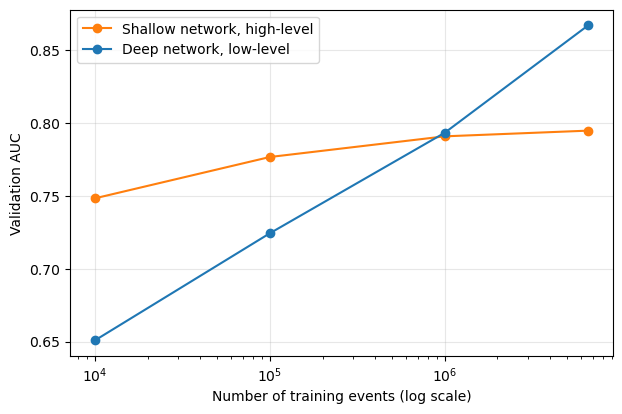

In [53]:
if FULL:
    sizes = [10_000, 100_000, 1_000_000]    # the full training set is added from Section 10
else:
    sizes = [1_000, 2_000, 4_000, 8_000]    # plus the full small-sample training set

curve = {"high": [], "low": []}
for n in sizes:
    run(f"Shallow high, n={n}", HIGH, depth=1, X_tr=X_train[:n], y_tr=y_train[:n], verbose=False)
    curve["high"].append(results.pop()["val_auc"])
    run(f"Deep low, n={n}", LOW, depth=int(best_low["depth"]), width=int(best_low["width"]),
        lr=float(best_low["lr"]), dropout=float(best_low["dropout"]),
        X_tr=X_train[:n], y_tr=y_train[:n], verbose=False)
    curve["low"].append(results.pop()["val_auc"])
    print(f"{n:>10,} training events: shallow high {curve['high'][-1]:.3f} | deep low {curve['low'][-1]:.3f}")

# add the models trained on the whole training set
sizes.append(len(X_train))
curve["high"].append(shallow_high_auc)               # shallow high-level from Section 6
curve["low"].append(float(best_low["val_auc"]))
print(f"{len(X_train):>10,} training events: shallow high {curve['high'][-1]:.3f} | deep low {curve['low'][-1]:.3f}")

plt.figure(figsize=(7, 4.5))
plt.plot(sizes, curve["high"], "o-", color="C1", label="Shallow network, high-level")
plt.plot(sizes, curve["low"], "o-", color="C0", label=f"Deep network, low-level")
plt.xscale("log")
plt.xlabel("Number of training events (log scale)")
plt.ylabel("Validation AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Question:** which curve is rising faster? Where would you guess the two curves cross?

## 12. What we learned

- The high-level features are computed from the low-level ones. They contain **no new information**, but they make the information **easier to learn**.
- With limited data, a network does better with the physicists' features. It doesn't have enough examples to work out those functions itself.
- A deeper network *can* learn them from the low-level features, and in the 2014 study it found information the high-level features had missed. But it needs a lot of data to do so.
- Adding the high-level features to the low-level ones helps at any data size: the expert features are a shortcut, not a substitute.

The general lesson: **there may be more information in your raw data, but learning to extract it can take a lot of data.** When data is limited, expert knowledge is valuable.

## 13. Exercises

1. **Wider or deeper?** With the best depth from Section 7, try a width of 512. With width 32, try depth 6. Which uses its extra capacity better?
2. **Training longer.** Pick one low-level model and train it with `patience=1000` (no early stopping) for 100 epochs, with `plot=True`. What happens to the validation AUC after the best epoch?
3. **Combinations.** Try depth 3 with dropout 0.2 *and* learning rate 0.003. Does combining two changes beat either alone?
4. **Physics symmetry (stretch).** The physics doesn't change if the whole event is rotated around the beam axis (all `phi` values shifted by the same angle) or reflected (all `eta` values change sign). Make extra training events by applying random rotations and reflections to the training set, before standardizing, then retrain a low-level model. Hint: in this file the `phi` columns run from about −1.74 to +1.74 rather than −π to π, so a full rotation is a shift of 2 × 1.74 with wrap-around.

In [54]:
# Exercise 1

In [55]:
# Exercise 2

In [56]:
# Exercise 3

In [57]:
# Exercise 4